# Part1: SHAP+随机森林模拟径流

Loading and preparing data...
Training runoff prediction model...
Model Performance - MSE: 0.000037, R2: 0.6739
Generating SHAP explanations...


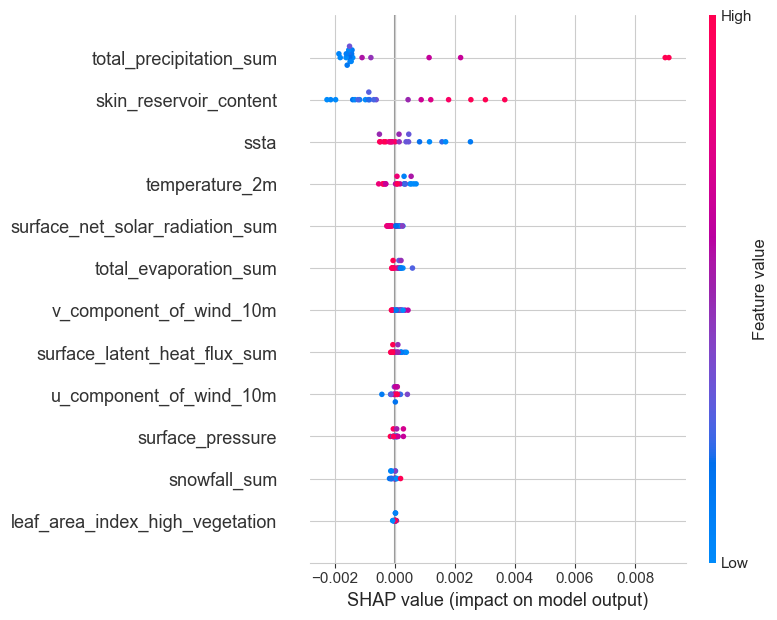

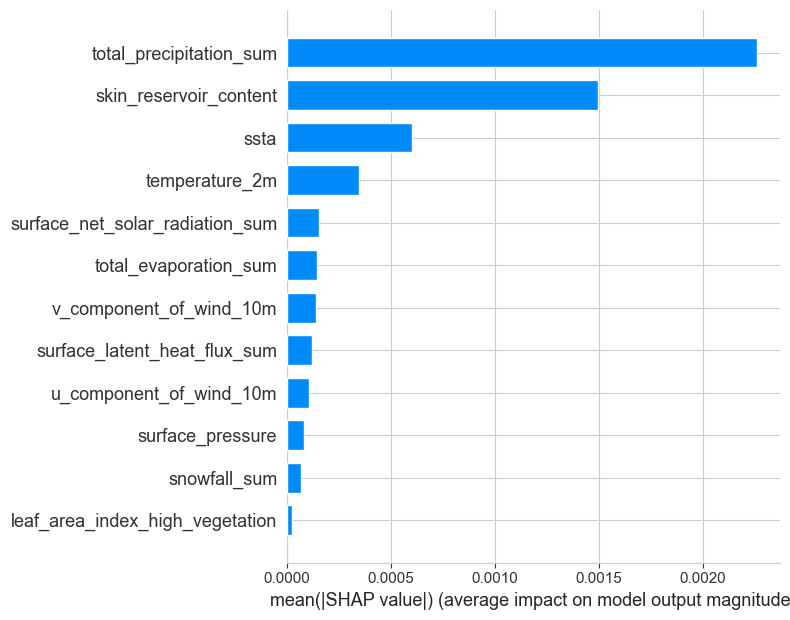


Script completed successfully!


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
import shap
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['font.family'] = 'Arial'

def load_and_prepare_data():
    df = pd.read_csv('geo.csv')
    
    feature_cols = [col for col in df.columns if col not in ['time', 'runoff_sum']]
    X = df[feature_cols]
    y = df['runoff_sum']
    
    return X, y, feature_cols

def train_model(X, y):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    model = RandomForestRegressor(n_estimators=100, random_state=42)
    model.fit(X_train_scaled, y_train)
    
    y_pred = model.predict(X_test_scaled)
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    
    print(f"Model Performance - MSE: {mse:.6f}, R2: {r2:.4f}")
    
    return model, scaler, X_train_scaled, X_test_scaled, y_test, y_pred

def explain_with_shap(model, X_train_scaled, X_test_scaled, feature_cols):
    explainer = shap.TreeExplainer(model)
    shap_values = explainer.shap_values(X_test_scaled[:20])
    
    shap.summary_plot(shap_values, X_test_scaled[:20], feature_names=feature_cols, show=False)
    plt.savefig('figure/runoff_shap_summary.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    shap.summary_plot(shap_values, X_test_scaled[:20], feature_names=feature_cols, 
                      plot_type="bar", show=False)
    plt.savefig('figure/runoff_shap_importance.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    return shap_values

if __name__ == "__main__":
    print("Loading and preparing data...")
    X, y, feature_cols = load_and_prepare_data()
    
    print("Training runoff prediction model...")
    model, scaler, X_train_scaled, X_test_scaled, y_test, y_pred = train_model(X, y)
    
    print("Generating SHAP explanations...")
    shap_values = explain_with_shap(model, X_train_scaled, X_test_scaled, feature_cols)
    
    print("\nScript completed successfully!")

# Part2: 使用ALIBI解释器解释径流预测模型

Loading and preparing data...
Training neural network model...
Neural Network Performance - MSE: 0.000694, R2: -5.1216
Generating ALE explanations...


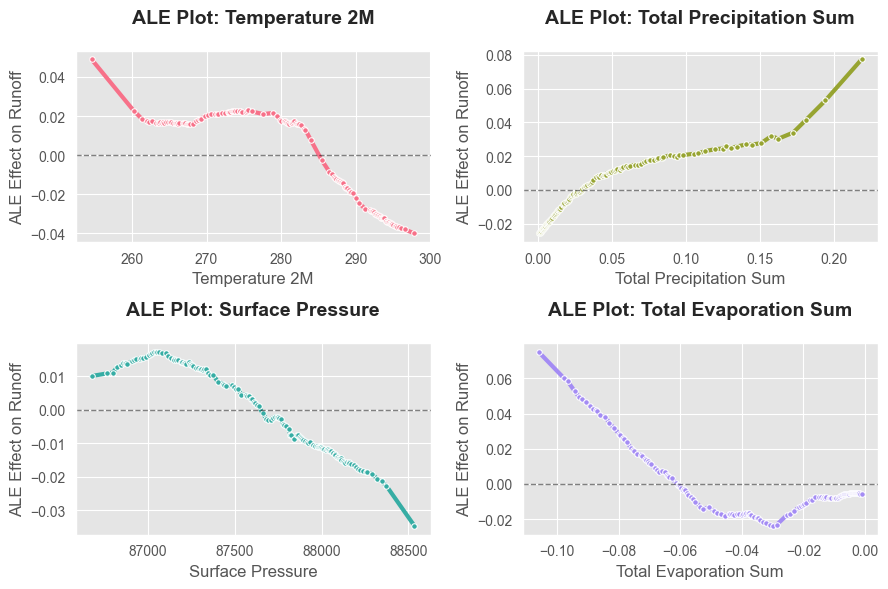

Creating ALE summary plot...


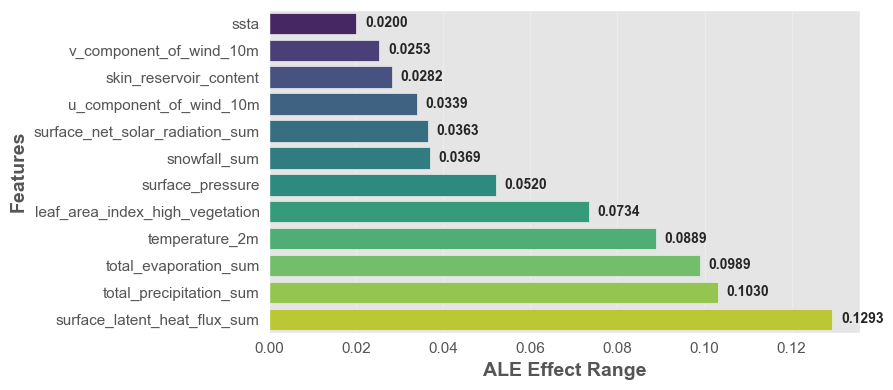


Top 5 features with highest ALE effect range:
                            feature  ale_range
11                             ssta   0.019973
7           v_component_of_wind_10m   0.025289
2            skin_reservoir_content   0.028215
6           u_component_of_wind_10m   0.033929
4   surface_net_solar_radiation_sum   0.036335

Script completed successfully!


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from alibi.explainers import ALE
import warnings
warnings.filterwarnings('ignore')

plt.style.use('ggplot')
plt.rcParams['font.family'] = 'Arial'


def load_and_prepare_data():
    df = pd.read_csv('geo.csv')
    
    feature_cols = [col for col in df.columns if col not in ['time', 'runoff_sum']]
    X = df[feature_cols]
    y = df['runoff_sum']
    
    return X, y, feature_cols

def train_neural_network(X, y):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    model = MLPRegressor(hidden_layer_sizes=(64, 32, 16), max_iter=1000, random_state=42, 
                        alpha=0.001, early_stopping=True, validation_fraction=0.1)
    model.fit(X_train_scaled, y_train)
    
    y_pred = model.predict(X_test_scaled)
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    
    print(f"Neural Network Performance - MSE: {mse:.6f}, R2: {r2:.4f}")
    
    return model, scaler, X_train_scaled, X_test_scaled, y_test, y_pred

def explain_with_ale(model, scaler, X_train, feature_cols):
    predict_fn = lambda x: model.predict(scaler.transform(x))
    
    ale_explainer = ALE(predict_fn, feature_names=feature_cols)
    
    X_train_original = pd.DataFrame(
        scaler.inverse_transform(X_train), 
        columns=feature_cols
    )
    
    explanation = ale_explainer.explain(X_train_original.values)
    
    key_features = ['temperature_2m', 'total_precipitation_sum', 'surface_pressure', 'total_evaporation_sum']
    available_features = [f for f in key_features if f in feature_cols]
    
    fig, axes = plt.subplots(2, 2, figsize=(9, 6))
    axes = axes.flatten()
    colors = sns.color_palette("husl", len(available_features))
    
    for i, feature in enumerate(available_features):
        if i < 4:
            feature_idx = feature_cols.index(feature)
            ale_values = explanation.ale_values[feature_idx].flatten()
            feature_values = explanation.feature_values[feature_idx].flatten()
            
            plot_df = pd.DataFrame({
                'feature_values': feature_values,
                'ale_values': ale_values
            })
            
            sns.lineplot(data=plot_df, x='feature_values', y='ale_values', ax=axes[i], 
                        color=colors[i], linewidth=3, marker='o', markersize=4)
            
            axes[i].set_title(f'ALE Plot: {feature.replace("_", " ").title()}', 
                            fontsize=14, fontweight='bold', pad=20)
            axes[i].set_xlabel(feature.replace('_', ' ').title(), fontsize=12)
            axes[i].set_ylabel('ALE Effect on Runoff', fontsize=12)
            axes[i].tick_params(labelsize=10)
            
            axes[i].axhline(y=0, color='black', linestyle='--', alpha=0.5, linewidth=1)
    
    for i in range(len(available_features), 4):
        axes[i].set_visible(False)
    
    plt.tight_layout()
    plt.savefig('figure/runoff_ale_explanation.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    return explanation

def plot_ale_summary(explanation, feature_cols):
    ale_values = explanation.ale_values
    feature_values = explanation.feature_values
    
    feature_effects = []
    for i, feature in enumerate(feature_cols):
        if i < len(ale_values):
            ale_range = np.max(ale_values[i]) - np.min(ale_values[i])
            feature_effects.append({'feature': feature, 'ale_range': ale_range})
    
    effect_df = pd.DataFrame(feature_effects).sort_values('ale_range', ascending=True)
    
    plt.figure(figsize=(9, 4))
    
    ax = sns.barplot(data=effect_df, y='feature', x='ale_range', 
                     palette='viridis', orient='h')
    
    ax.set_xlabel('ALE Effect Range', fontsize=14, fontweight='bold')
    ax.set_ylabel('Features', fontsize=14, fontweight='bold')
    
    
    for i, (idx, row) in enumerate(effect_df.iterrows()):
        ax.text(row['ale_range'] + 0.002, i, f'{row["ale_range"]:.4f}', 
                va='center', ha='left', fontsize=10, fontweight='bold')
    
    ax.tick_params(labelsize=11)
    ax.grid(True, alpha=0.3, axis='x')
    
    plt.tight_layout()
    plt.savefig('figure/ale_feature_importance.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    return effect_df

if __name__ == "__main__":
    print("Loading and preparing data...")
    X, y, feature_cols = load_and_prepare_data()
    
    print("Training neural network model...")
    model, scaler, X_train_scaled, X_test_scaled, y_test, y_pred = train_neural_network(X, y)
    
    print("Generating ALE explanations...")
    explanation = explain_with_ale(model, scaler, X_train_scaled, feature_cols)
    
    print("Creating ALE summary plot...")
    effect_df = plot_ale_summary(explanation, feature_cols)
    
    print("\nTop 5 features with highest ALE effect range:")
    print(effect_df.head())
    
    print("\nScript completed successfully!")